In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones, duraciones medias y desviaciones típicas (en semanas) se adjunta. La actividad E se va a subcontratar y la desviación típica de su duración depende del contratista elegido. El cliente exige terminar en 28 semanas con una probabilidad de al menos el 90 %.

In [4]:
pregunta_1 = "1. Determine la duración media del proyecto y la ruta crítica. ¿Está en ella la actividad subcontratada?  "
pregunta_2 = "2. Calcule la varianza del proyecto en función de la desviación típica σ de E.  "
pregunta_3 = "3. ¿Qué desviación típica máxima puede tener E para cumplir la exigencia del cliente?  "
pregunta_4 = "4. Si ningún contratista garantiza esa dispersión, ¿cuántas semanas habría que reducir la duración media del proyecto (manteniendo las varianzas) para cumplir con el contratista de σ = 1,5?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Determine la duración media del proyecto y la ruta crítica. ¿Está en ella la actividad subcontratada?  

2. Calcule la varianza del proyecto en función de la desviación típica σ de E.  

3. ¿Qué desviación típica máxima puede tener E para cumplir la exigencia del cliente?  

4. Si ningún contratista garantiza esa dispersión, ¿cuántas semanas habría que reducir la duración media del proyecto (manteniendo las varianzas) para cumplir con el contratista de σ = 1,5?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado (σ de E por determinar)"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, standard_deviation
    ('A'     , '---'      , 3       , 0.1               ),
    ('B'     , '---'      , 7       , 0.1               ),
    ('C'     , 'A'        , 6       , 0.6               ),
    ('D'     , 'C'        , 3       , 0.6               ),
    ('E'     , 'D'        , 2       , np.nan               ),
    ('F'     , 'B,E'      , 5       , 1                 ),
    ('G'     , 'E'        , 3       , 0.3               ),
    ('H'     , 'G'        , 1       , 0.1               ),
    ('I'     , 'H'        , 2       , 0.4               ),
    ('J'     , 'I'        , 6       , 0.1               ),
], columns=['activity', 'predecessor', 'duration', 'standard_deviation']).set_index('activity')
datos_enunciado

,predecessor,duration,standard_deviation
activity,,,
A,---,3,0.1
B,---,7,0.1
C,A,6,0.6
D,C,3,0.6
E,D,2,NaN
F,"B,E",5,1.0
G,E,3,0.3
H,G,1,0.1
I,H,2,0.4


El proyecto corresponde a la organización de un congreso científico; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Definición del programa y fechas',
    'B': 'Reserva de la sede',
    'C': 'Convocatoria de comunicaciones',
    'D': 'Página web e inscripciones',
    'E': 'Contratación de ponentes invitados',
    'F': 'Revisión de los trabajos recibidos',
    'G': 'Elaboración del programa definitivo',
    'H': 'Contratación de catering y viajes',
    'I': 'Edición del libro de actas',
    'J': 'Preparación de salas y audiovisuales',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Definición del programa y fechas
B,Reserva de la sede
C,Convocatoria de comunicaciones
D,Página web e inscripciones
E,Contratación de ponentes invitados
F,Revisión de los trabajos recibidos
G,Elaboración del programa definitivo
H,Contratación de catering y viajes
I,Edición del libro de actas
J,Preparación de salas y audiovisuales


# Resolución

In [7]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
X, plazo, probabilidad_objetivo = 'E', 28, 0.9

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Determine la duración media del proyecto y la ruta crítica. ¿Está en ella la actividad subcontratada?  

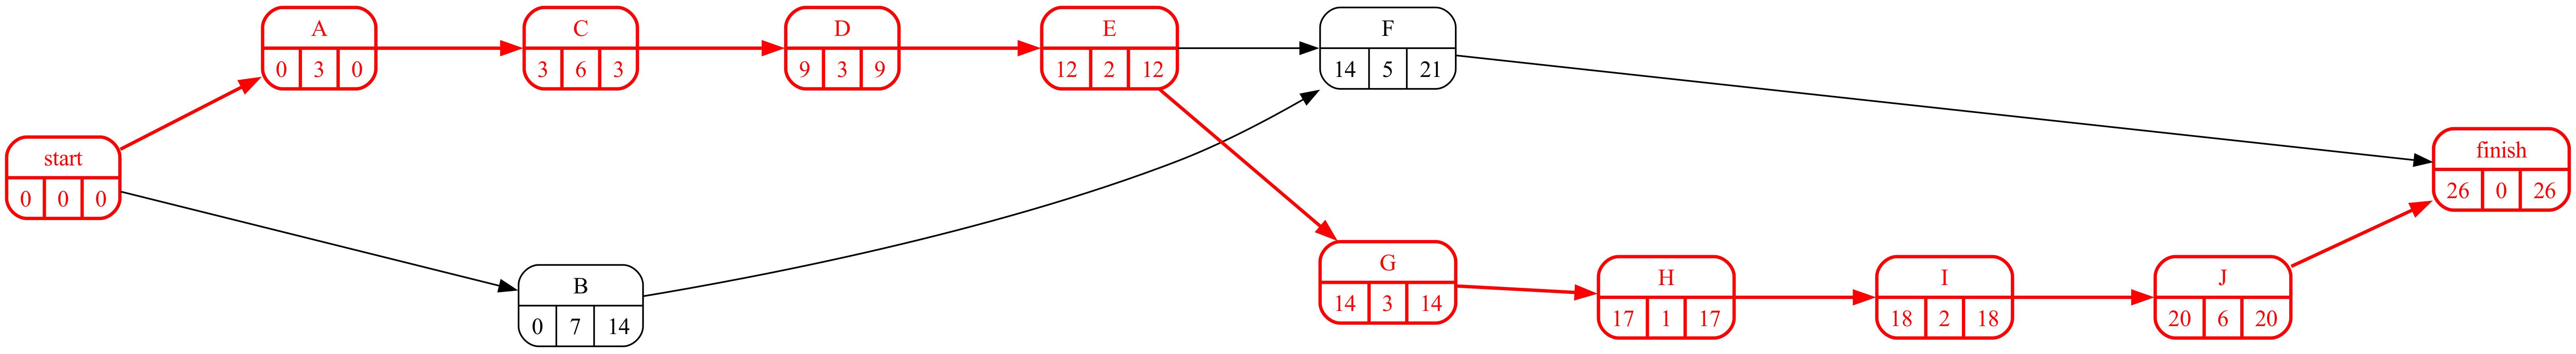

In [9]:
#| fig-cap: "Grafo Roy con tiempos y camino crítico"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

In [10]:
duracion_media = proyecto.duration(datos_proyecto['duration'])
criticas = sorted(set(a for acts in proyecto.critical_path(datos_proyecto['duration']).values() for a in acts))
Markdown(f'Duración media {duracion_media} semanas; ruta crítica {" - ".join(criticas)}. {X} {"sí" if X in criticas else "no"} está en ella.')

Duración media 26 semanas; ruta crítica A - C - D - E - G - H - I - J. E sí está en ella.

## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. Calcule la varianza del proyecto en función de la desviación típica σ de E.  

In [12]:
var_resto = float((datos_proyecto.loc[[a for a in criticas if a != X], 'standard_deviation'] ** 2).sum())
Markdown(f'Varianza del proyecto = varianza del resto de la ruta crítica + σ² = {var_resto:.3f} + σ².')

Varianza del proyecto = varianza del resto de la ruta crítica + σ² = 1.000 + σ².

## Apartado 3

In [13]:
display(Markdown(pregunta_3))

3. ¿Qué desviación típica máxima puede tener E para cumplir la exigencia del cliente?  

Se necesita $P(T \le plazo) \ge p$, es decir, $\dfrac{plazo - \mu}{\sigma_T} \ge z_p$, luego $\sigma_T \le \dfrac{plazo - \mu}{z_p}$ y $\sigma_X^2 \le \sigma_T^2 - \sigma_{resto}^2$.

In [14]:
z_p = norm.ppf(probabilidad_objetivo)
sigma_T_max = (plazo - duracion_media) / z_p
var_X_max = sigma_T_max ** 2 - var_resto
sigma_X_max = np.sqrt(var_X_max) if var_X_max > 0 else 0.0
Markdown(f'''σ_T ≤ ({plazo} − {duracion_media}) / {z_p:.3f} = {sigma_T_max:.3f}; σ_X² ≤ {sigma_T_max:.3f}² − {var_resto:.3f} = {var_X_max:.3f}, luego **σ_X ≤ {sigma_X_max:.2f} semanas**{" (ningún contratista vale: ni con σ = 0 se alcanza la probabilidad)" if var_X_max <= 0 else ""}.''')

σ_T ≤ (28 − 26) / 1.282 = 1.561; σ_X² ≤ 1.561² − 1.000 = 1.435, luego **σ_X ≤ 1.20 semanas**.

## Apartado 4

In [15]:
display(Markdown(pregunta_4))

4. Si ningún contratista garantiza esa dispersión, ¿cuántas semanas habría que reducir la duración media del proyecto (manteniendo las varianzas) para cumplir con el contratista de σ = 1,5?  

In [16]:
sigma_contratista = 1.5
sigma_T = np.sqrt(var_resto + sigma_contratista ** 2)
media_necesaria = plazo - z_p * sigma_T
reduccion = int(np.ceil(duracion_media - media_necesaria))
Markdown(f'Con σ_X = 1,5, σ_T = {sigma_T:.3f} y hace falta μ ≤ {plazo} − {z_p:.3f} × {sigma_T:.3f} = {media_necesaria:.2f}: '
         f'reducir la duración media en {max(reduccion, 0)} semana(s) (suponiendo que la ruta crítica no cambia al acortar).')

Con σ_X = 1,5, σ_T = 1.803 y hace falta μ ≤ 28 − 1.282 × 1.803 = 25.69: reducir la duración media en 1 semana(s) (suponiendo que la ruta crítica no cambia al acortar).